<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

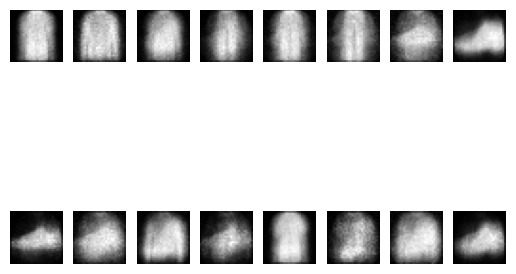

GAN training completed


In [3]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt
(x,y),(xt,yt)=tf.keras.datasets.fashion_mnist.load_data(); x=x[:10000].astype('float32')/255; x=x.reshape(-1,784);

# VAE Setup
latent = 16

# Encoder
inp = tf.keras.Input((784,))
z1 = tf.keras.layers.Dense(128, activation='relu')(inp)
mu = tf.keras.layers.Dense(latent)(z1)
logv = tf.keras.layers.Dense(latent)(z1)

def sample(args):
    mu, lv = args
    return mu + tf.exp(.5 * lv) * tf.random.normal(tf.shape(mu))

z = tf.keras.layers.Lambda(sample)([mu, logv])
encoder = tf.keras.Model(inp, [mu, logv, z])

# Decoder
dec_inp = tf.keras.Input((latent,))
dz1 = tf.keras.layers.Dense(128, activation='relu')(dec_inp)
out = tf.keras.layers.Dense(784, activation='sigmoid')(dz1)
decoder = tf.keras.Model(dec_inp, out)

# Custom VAE Model subclassing for Keras 3 compatibility
class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name="total_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            mu, logv, z = self.encoder(data)
            reconstruction = self.decoder(z)
            # reconstruction loss scaled over the input size (784 dimensions)
            recon_loss = tf.reduce_mean(tf.reduce_sum(tf.keras.losses.binary_crossentropy(data, reconstruction), axis=-1))
            kl_loss = -0.5 * tf.reduce_mean(tf.reduce_sum(1 + logv - tf.square(mu) - tf.exp(logv), axis=-1))
            total_loss = recon_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        return {"loss": self.total_loss_tracker.result()}

vae = VAE(encoder, decoder)
vae.compile(optimizer='adam')
vae.fit(x, epochs=3, batch_size=128, verbose=0)

# Generate samples
samples = decoder(tf.random.normal((16, latent))).numpy()
fig, ax = plt.subplots(2, 8)
for i in range(16):
    ax.flat[i].imshow(samples[i].reshape(28, 28), cmap='gray')
    ax.flat[i].axis('off')
plt.show()

# Small GAN
G=tf.keras.Sequential([tf.keras.layers.Input((100,)),tf.keras.layers.Dense(128,activation='relu'),tf.keras.layers.Dense(784,activation='sigmoid')]); D=tf.keras.Sequential([tf.keras.layers.Input((784,)),tf.keras.layers.Dense(128,activation='relu'),tf.keras.layers.Dense(1,activation='sigmoid')]); D.compile('adam','binary_crossentropy')
D.trainable=False; gan=tf.keras.Sequential([G,D]); gan.compile('adam','binary_crossentropy')
for _ in range(300):
 real=x[np.random.randint(len(x),size=32)]; noise=np.random.normal(size=(32,100)); D.trainable=True; D.train_on_batch(real,np.ones((32,1))); D.train_on_batch(G.predict(noise,verbose=0),np.zeros((32,1))); D.trainable=False; gan.train_on_batch(noise,np.ones((32,1)))
print('GAN training completed')